# Rajuk Class-Balanced CUDA SVM — CNN-Style Report Edition

This version addresses the weak moderate/positive recall of the f2 notebook. It uses a frozen ImageNet-pretrained ResNet18 only as a CUDA feature extractor; the classifier is still a multiclass SVM ensemble.

Important balancing guarantees:

- The SVM training matrix contains exactly the same number of negative, moderate, and positive images.
- Every bootstrap member independently receives exactly the same number of examples from all three classes.
- The largest original class count is used as the per-class target: every majority image is preserved while moderate and positive examples are oversampled to the same count.
- Model selection prioritizes validation macro-F1 and balanced accuracy, not majority-dominated accuracy.

## 1. Imports, CUDA, and configuration

In [1]:
import gc
import os
import re
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss,
    classification_report, confusion_matrix
)

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        'CUDA is required. Install a CUDA-enabled PyTorch build and a current NVIDIA driver.'
    )

torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda')
torch.backends.cudnn.benchmark = True

PROJECT_ROOT  = Path(r'D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files')
AUGMENTED_DIR = PROJECT_ROOT / 'Augmented_raw_data'
REAL_DIR      = PROJECT_ROOT / 'raw_data' / 'final train image'
XLSX_PATH     = PROJECT_ROOT / 'Rajuk_ML_DataSet.xlsx'
CSV_PATH      = PROJECT_ROOT / 'Real ML_DataSet.csv'
OUTPUT_DIR    = Path.cwd()

CLASS_NAMES = ['negative', 'moderate', 'positive']
ALLOWED_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
TEST_FRACTION = 0.20
VAL_FRACTION = 0.10

DEEP_BATCH_SIZE = 32
DATALOADER_WORKERS = 0  # safest setting for a Windows Jupyter kernel
BALANCE_TARGET = 'max'
CUDA_SVM_EPOCHS = 160
CUDA_SVM_LR = 0.02
RFF_COMPONENTS = 512

REFERENCE_TEST_ACCURACY = 0.5467
REFERENCE_TEST_MACRO_F1 = 0.4208

BAGGING_CANDIDATES = [
    dict(kernel='linear', C=0.01, gamma='scale', n_estimators=15, max_samples=0.75, max_features=0.80),
    dict(kernel='linear', C=0.03, gamma='scale', n_estimators=15, max_samples=0.80, max_features=0.85),
    dict(kernel='linear', C=0.05, gamma='scale', n_estimators=17, max_samples=0.85, max_features=0.90),
    dict(kernel='linear', C=0.10, gamma='scale', n_estimators=17, max_samples=0.90, max_features=0.90),
]

MODEL_PATH = OUTPUT_DIR / 'rajuk_balanced_cuda_svm.pkl'
MISCLASSIFIED_CSV = OUTPUT_DIR / 'misclassified_images_balanced_cuda_svm.csv'
BIAS_VARIANCE_PNG = OUTPUT_DIR / 'bias_variance_balanced_cuda_svm.png'

print(f'CUDA device       : {torch.cuda.get_device_name(0)}')
print(f'PyTorch CUDA build: {torch.version.cuda}')
print(f'Output directory  : {OUTPUT_DIR.resolve()}')

CUDA device       : NVIDIA GeForce GTX 1650
PyTorch CUDA build: 12.4
Output directory  : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4


## 2. Load labels and create the same subject-level input split

In [2]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(frame, target):
    return next((column for column in frame.columns if normalize_header(column) == target), None)

def normalize_level(value):
    if pd.isna(value):
        return None
    return {
        'n': 'negative', 'negative': 'negative',
        'm': 'moderate', 'moderate': 'moderate',
        'p': 'positive', 'positive': 'positive',
    }.get(str(value).strip().lower())

if XLSX_PATH.exists():
    labels_df = pd.read_excel(XLSX_PATH)
    label_source = XLSX_PATH
elif CSV_PATH.exists():
    labels_df = pd.read_csv(CSV_PATH)
    label_source = CSV_PATH
else:
    raise FileNotFoundError(f'No label file found under {PROJECT_ROOT}.')

level_column = (
    find_column(labels_df, 'levelpositivemoderatenegative')
    or find_column(labels_df, 'level')
)
if level_column is None:
    raise ValueError('The positive/moderate/negative level column was not found.')

class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}
label_map = {}
for row_index, value in enumerate(labels_df[level_column].tolist(), start=1):
    normalized = normalize_level(value)
    if normalized is not None:
        label_map[row_index] = class_to_index[normalized]

print(f'Loaded {len(label_map):,} valid labels from {label_source.name}.')

Loaded 372 valid labels from Real ML_DataSet.csv.


In [3]:
def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.strip().lower())
    return int(match.group(1)) if match else None

def collect_records(directory):
    records = []
    skipped = 0
    if not directory.exists():
        raise FileNotFoundError(directory)
    for path in directory.rglob('*'):
        if not (path.is_file() and path.suffix.lower() in ALLOWED_EXTS):
            continue
        image_id = parse_image_index(path.stem)
        if image_id is None or image_id not in label_map:
            skipped += 1
            continue
        records.append((path, label_map[image_id], image_id))
    return records, skipped

augmented_records, skipped_augmented = collect_records(AUGMENTED_DIR)
real_records, skipped_real = collect_records(REAL_DIR)

unique_ids = np.array(sorted({record[2] for record in real_records}))
unique_labels = np.array([label_map[image_id] for image_id in unique_ids])

trainval_ids, test_ids = train_test_split(
    unique_ids,
    test_size=TEST_FRACTION,
    random_state=SEED,
    stratify=unique_labels,
)
trainval_labels = np.array([label_map[image_id] for image_id in trainval_ids])
train_ids, val_ids = train_test_split(
    trainval_ids,
    test_size=VAL_FRACTION / (1.0 - TEST_FRACTION),
    random_state=SEED,
    stratify=trainval_labels,
)

train_ids, val_ids, test_ids = set(train_ids), set(val_ids), set(test_ids)
all_records = augmented_records + real_records
train_records = [record for record in all_records if record[2] in train_ids]
val_records = [record for record in all_records if record[2] in val_ids]
test_records = [record for record in all_records if record[2] in test_ids]

assert train_ids.isdisjoint(val_ids | test_ids)
assert val_ids.isdisjoint(test_ids)

def print_record_distribution(name, records):
    counts = np.bincount([record[1] for record in records], minlength=len(CLASS_NAMES))
    print(f'\n{name}: {len(records):,} images')
    for class_name, count in zip(CLASS_NAMES, counts):
        print(f'  {class_name:10s}: {count:,}')

print(f'Augmented images: {len(augmented_records):,}')
print(f'Real images     : {len(real_records):,}')
print(f'Skipped         : {skipped_augmented + skipped_real:,}')
print_record_distribution('Training before balancing', train_records)
print_record_distribution('Validation', val_records)
print_record_distribution('Test', test_records)

Augmented images: 5,968
Real images     : 373
Skipped         : 17

Training before balancing: 4,420 images
  negative  : 2,720
  moderate  : 969
  positive  : 731

Validation: 646 images
  negative  : 408
  moderate  : 136
  positive  : 102

Test: 1,275 images
  negative  : 782
  moderate  : 289
  positive  : 204


## 3. CUDA ResNet18 embeddings

The pretrained network is frozen and used only to convert each image into a 1,536-dimensional multi-scale descriptor. Average and maximum pooled features from ResNet layer3 and layer4 preserve both texture and semantic information. Classification remains entirely SVM-based.

In [4]:
resnet_weights = models.ResNet18_Weights.DEFAULT
image_transform = resnet_weights.transforms()
resnet_backbone = models.resnet18(weights=resnet_weights).to(DEVICE).eval()
for parameter in resnet_backbone.parameters():
    parameter.requires_grad = False

def extract_multiscale_resnet_features(images):
    """Combine average/max-pooled layer3 and layer4 descriptors (1,536-D)."""
    x = resnet_backbone.conv1(images)
    x = resnet_backbone.bn1(x)
    x = resnet_backbone.relu(x)
    x = resnet_backbone.maxpool(x)
    x = resnet_backbone.layer1(x)
    x = resnet_backbone.layer2(x)
    layer3 = resnet_backbone.layer3(x)
    layer4 = resnet_backbone.layer4(layer3)
    descriptors = torch.cat([
        F.adaptive_avg_pool2d(layer3, 1).flatten(1),
        F.adaptive_max_pool2d(layer3, 1).flatten(1),
        F.adaptive_avg_pool2d(layer4, 1).flatten(1),
        F.adaptive_max_pool2d(layer4, 1).flatten(1),
    ], dim=1)
    return F.normalize(descriptors.float(), p=2, dim=1)

class ImageRecordDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label, image_id = self.records[index]
        with Image.open(path) as image:
            tensor = image_transform(image.convert('RGB'))
        return tensor, label, image_id, str(path)

def extract_embeddings(records, split_name):
    loader = DataLoader(
        ImageRecordDataset(records),
        batch_size=DEEP_BATCH_SIZE,
        shuffle=False,
        num_workers=DATALOADER_WORKERS,
        pin_memory=True,
    )
    feature_batches, labels, groups, paths = [], [], [], []
    processed = 0
    with torch.inference_mode():
        for images, batch_labels, batch_groups, batch_paths in loader:
            images = images.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                embeddings = extract_multiscale_resnet_features(images)
            feature_batches.append(embeddings.cpu().numpy().astype(np.float32))
            labels.append(batch_labels.numpy().astype(np.int64))
            groups.append(batch_groups.numpy().astype(np.int64))
            paths.extend(batch_paths)
            processed += len(images)
            print(f'  {split_name}: {processed:,}/{len(records):,}', end='\r')
    print()
    return (
        np.concatenate(feature_batches),
        np.concatenate(labels),
        np.concatenate(groups),
        [Path(path) for path in paths],
    )

X_train_all, y_train_all, train_groups, train_paths = extract_embeddings(train_records, 'train')
X_val, y_val, val_groups, val_paths = extract_embeddings(val_records, 'validation')
X_test, y_test, test_groups, test_paths = extract_embeddings(test_records, 'test')
print(f'Embedding dimension: {X_train_all.shape[1]}')

  train: 4,420/4,420
  validation: 646/646
  test: 1,275/1,275
Embedding dimension: 1536


## 4. Create an exactly balanced SVM training matrix

In [5]:
def make_exactly_balanced(X, y, groups, paths, random_state, target=BALANCE_TARGET):
    rng = np.random.default_rng(random_state)
    counts = np.bincount(y, minlength=len(CLASS_NAMES))
    if target == 'median':
        per_class = int(np.median(counts))
    elif target == 'max':
        per_class = int(counts.max())
    elif target == 'min':
        per_class = int(counts.min())
    else:
        per_class = int(target)

    selected = []
    for class_index in range(len(CLASS_NAMES)):
        candidates = np.flatnonzero(y == class_index)
        chosen = rng.choice(
            candidates,
            size=per_class,
            replace=len(candidates) < per_class,
        )
        selected.append(chosen)

    selected = np.concatenate(selected)
    rng.shuffle(selected)
    balanced_X = X[selected]
    balanced_y = y[selected]
    balanced_groups = groups[selected]
    balanced_paths = [paths[index] for index in selected]

    balanced_counts = np.bincount(balanced_y, minlength=len(CLASS_NAMES))
    assert len(set(balanced_counts.tolist())) == 1
    return balanced_X, balanced_y, balanced_groups, balanced_paths, selected

X_train, y_train, train_groups_balanced, train_paths_balanced, train_balance_indices = make_exactly_balanced(
    X_train_all, y_train_all, train_groups, train_paths, random_state=SEED
)

before_counts = np.bincount(y_train_all, minlength=len(CLASS_NAMES))
after_counts = np.bincount(y_train, minlength=len(CLASS_NAMES))
balance_table = pd.DataFrame({
    'class': CLASS_NAMES,
    'before': before_counts,
    'after': after_counts,
})
display(balance_table)
assert after_counts[0] == after_counts[1] == after_counts[2]
print(f'EXACT BALANCE CONFIRMED: {after_counts[0]:,} training images per class.')

,class,before,after
0,negative,2720,2720
1,moderate,969,2720
2,positive,731,2720


EXACT BALANCE CONFIRMED: 2,720 training images per class.


## 5. CUDA scaling and class-balanced bagged SVM

In [6]:
class CudaStandardScaler:
    def fit(self, X):
        tensor = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        self.mean_ = tensor.mean(dim=0).cpu().numpy().astype(np.float32)
        self.scale_ = tensor.std(dim=0, unbiased=False).clamp_min(1e-8).cpu().numpy().astype(np.float32)
        return self

    def transform(self, X):
        tensor = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        mean = torch.as_tensor(self.mean_, dtype=torch.float32, device=DEVICE)
        scale = torch.as_tensor(self.scale_, dtype=torch.float32, device=DEVICE)
        return ((tensor - mean) / scale).cpu().numpy().astype(np.float32)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

scaler = CudaStandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
del X_train  # the scaled matrix is now the only balanced training copy needed
gc.collect()
print('CUDA scaling complete.')

CUDA scaling complete.


In [7]:
class CudaSVMMember:
    def __init__(self, kernel, C, gamma, n_classes, random_state):
        self.kernel = kernel
        self.C = float(C)
        self.gamma = gamma
        self.n_classes = int(n_classes)
        self.random_state = int(random_state)
        self.classes_ = np.arange(n_classes, dtype=np.int64)

    def _transform_gpu(self, X):
        if self.kernel == 'linear':
            return X
        weight = torch.as_tensor(self.rff_weight_, dtype=torch.float32, device=DEVICE)
        bias = torch.as_tensor(self.rff_bias_, dtype=torch.float32, device=DEVICE)
        return np.sqrt(2.0 / weight.shape[1]) * torch.cos(X @ weight + bias)

    def fit(self, X, y):
        # Accept pre-indexed CUDA tensors so bagging never creates large NumPy copies.
        X_gpu = X.to(device=DEVICE, dtype=torch.float32) if torch.is_tensor(X) else torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        y_gpu = y.to(device=DEVICE, dtype=torch.long) if torch.is_tensor(y) else torch.as_tensor(y, dtype=torch.long, device=DEVICE)

        if self.kernel == 'rbf':
            variance = max(float(X_gpu.var(unbiased=False).item()), 1e-8)
            gamma_value = 1.0 / (X_gpu.shape[1] * variance) if self.gamma == 'scale' else float(self.gamma)
            generator = torch.Generator(device=DEVICE)
            generator.manual_seed(self.random_state)
            rff_weight = torch.randn(
                X_gpu.shape[1], RFF_COMPONENTS, generator=generator, device=DEVICE
            ) * np.sqrt(2.0 * gamma_value)
            rff_bias = 2 * np.pi * torch.rand(RFF_COMPONENTS, generator=generator, device=DEVICE)
            mapped = np.sqrt(2.0 / RFF_COMPONENTS) * torch.cos(X_gpu @ rff_weight + rff_bias)
            self.rff_weight_ = rff_weight.cpu().numpy().astype(np.float32)
            self.rff_bias_ = rff_bias.cpu().numpy().astype(np.float32)
        else:
            mapped = X_gpu
            self.rff_weight_ = None
            self.rff_bias_ = None

        n_samples, n_features = mapped.shape
        weight = torch.zeros(
            self.n_classes, n_features, device=DEVICE, requires_grad=True
        )
        bias = torch.zeros(self.n_classes, device=DEVICE, requires_grad=True)
        optimizer = torch.optim.AdamW([weight, bias], lr=CUDA_SVM_LR, weight_decay=0)
        non_target = 1.0 - F.one_hot(y_gpu, num_classes=self.n_classes).float()

        for _ in range(CUDA_SVM_EPOCHS):
            optimizer.zero_grad(set_to_none=True)
            scores = mapped @ weight.T + bias
            correct_scores = scores.gather(1, y_gpu[:, None])
            margins = F.relu(scores - correct_scores + 1.0) * non_target
            hinge = margins.square().sum(dim=1).mean()
            regularizer = 0.5 * weight.square().sum() / (self.C * n_samples)
            loss = hinge + regularizer
            loss.backward()
            optimizer.step()

        self.weight_ = weight.detach().cpu().numpy().astype(np.float32)
        self.bias_ = bias.detach().cpu().numpy().astype(np.float32)
        return self

    def decision_function(self, X):
        with torch.inference_mode():
            tensor = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
            mapped = self._transform_gpu(tensor)
            weight = torch.as_tensor(self.weight_, dtype=torch.float32, device=DEVICE)
            bias = torch.as_tensor(self.bias_, dtype=torch.float32, device=DEVICE)
            return (mapped @ weight.T + bias).cpu().numpy()

    def predict_proba(self, X):
        scores = torch.as_tensor(self.decision_function(X), device=DEVICE)
        return torch.softmax(scores, dim=1).cpu().numpy()

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)


class BalancedCudaBaggedSVM:
    def __init__(self, config, random_state=SEED):
        self.config = dict(config)
        self.random_state = int(random_state)

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.int64)
        self.classes_ = np.arange(len(CLASS_NAMES), dtype=np.int64)
        counts = np.bincount(y, minlength=len(self.classes_))
        if len(set(counts.tolist())) != 1:
            raise ValueError(f'Training input is not exactly balanced: {counts.tolist()}')

        # Keep exactly one copy of the complete balanced matrix on CUDA.
        # Bootstrap subsets are indexed on-device, avoiding 30–50 MB NumPy copies.
        X_gpu_full = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
        y_gpu_full = torch.as_tensor(y, dtype=torch.long, device=DEVICE)

        rng = np.random.default_rng(self.random_state)
        per_class_available = counts[0]
        per_class_bootstrap = max(1, int(round(per_class_available * self.config['max_samples'])))
        feature_count = max(1, int(round(X.shape[1] * self.config['max_features'])))
        self.estimators_ = []
        self.estimators_features_ = []

        for member_index in range(self.config['n_estimators']):
            bootstrap_parts = []
            for class_index in self.classes_:
                class_indices = np.flatnonzero(y == class_index)
                bootstrap_parts.append(
                    rng.choice(class_indices, size=per_class_bootstrap, replace=True)
                )
            bootstrap_indices = np.concatenate(bootstrap_parts)
            rng.shuffle(bootstrap_indices)
            member_counts = np.bincount(y[bootstrap_indices], minlength=len(self.classes_))
            assert member_counts[0] == member_counts[1] == member_counts[2]

            feature_indices = rng.choice(
                X.shape[1], size=feature_count, replace=False
            ).astype(np.int64)
            member = CudaSVMMember(
                kernel=self.config['kernel'],
                C=self.config['C'],
                gamma=self.config['gamma'],
                n_classes=len(self.classes_),
                random_state=self.random_state + member_index + 1,
            )
            row_index_gpu = torch.as_tensor(bootstrap_indices, dtype=torch.long, device=DEVICE)
            feature_index_gpu = torch.as_tensor(feature_indices, dtype=torch.long, device=DEVICE)
            member_X_gpu = X_gpu_full[
                row_index_gpu[:, None], feature_index_gpu[None, :]
            ]
            member_y_gpu = y_gpu_full[row_index_gpu]
            member.fit(member_X_gpu, member_y_gpu)
            self.estimators_.append(member)
            self.estimators_features_.append(feature_indices)
            del member_X_gpu, member_y_gpu, row_index_gpu, feature_index_gpu

            if (member_index + 1) % 5 == 0 or member_index + 1 == self.config['n_estimators']:
                print(
                    f'  member {member_index + 1:>2}/{self.config["n_estimators"]} | '
                    f'{member_counts[0]} images/class'
                )
        del X_gpu_full, y_gpu_full
        torch.cuda.empty_cache()
        return self

    def predict_proba(self, X):
        probabilities = [
            estimator.predict_proba(X[:, feature_indices])
            for estimator, feature_indices in zip(self.estimators_, self.estimators_features_)
        ]
        return np.mean(probabilities, axis=0)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

def make_model(config, random_state):
    return BalancedCudaBaggedSVM(config, random_state)

## 6. Select the SVM using macro-F1 and balanced accuracy

In [8]:
candidate_rows = []
candidate_models = []

for candidate_index, config in enumerate(BAGGING_CANDIDATES, start=1):
    print(f'\nCandidate {candidate_index}/{len(BAGGING_CANDIDATES)}: {config}')
    model = make_model(config, SEED + candidate_index)
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_val_scaled)
    probabilities = model.predict_proba(X_val_scaled)

    row = {
        'candidate': candidate_index,
        **config,
        'val_macro_f1': f1_score(y_val, predictions, average='macro'),
        'val_balanced_accuracy': balanced_accuracy_score(y_val, predictions),
        'val_accuracy': accuracy_score(y_val, predictions),
        'val_log_loss': log_loss(y_val, probabilities, labels=np.arange(len(CLASS_NAMES))),
    }
    candidate_rows.append(row)
    candidate_models.append(model)
    print(
        f"macro-F1={row['val_macro_f1']:.4f} | "
        f"balanced_acc={row['val_balanced_accuracy']:.4f} | "
        f"accuracy={row['val_accuracy']:.4f}"
    )

candidate_results = pd.DataFrame(candidate_rows)
ranked = candidate_results.sort_values(
    ['val_macro_f1', 'val_balanced_accuracy', 'val_accuracy', 'val_log_loss'],
    ascending=[False, False, False, True],
).reset_index(drop=True)

class SoftVotingSVM:
    def __init__(self, models_, weights_):
        self.models_ = list(models_)
        weights_array = np.asarray(weights_, dtype=np.float64)
        self.weights_ = weights_array / weights_array.sum()

    def predict_proba(self, X):
        return sum(
            weight * model.predict_proba(X)
            for model, weight in zip(self.models_, self.weights_)
        )

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

top_candidate_ids = ranked['candidate'].head(3).astype(int).tolist()
validation_probability_cache = {
    candidate_id: candidate_models[candidate_id - 1].predict_proba(X_val_scaled)
    for candidate_id in top_candidate_ids
}
blend_rows = []
for left_position, left_id in enumerate(top_candidate_ids):
    for right_id in top_candidate_ids[left_position + 1:]:
        for left_weight in [0.25, 0.50, 0.75]:
            probabilities = (
                left_weight * validation_probability_cache[left_id]
                + (1.0 - left_weight) * validation_probability_cache[right_id]
            )
            predictions = probabilities.argmax(axis=1)
            blend_rows.append({
                'left_candidate': left_id,
                'right_candidate': right_id,
                'left_weight': left_weight,
                'right_weight': 1.0 - left_weight,
                'val_macro_f1': f1_score(y_val, predictions, average='macro'),
                'val_balanced_accuracy': balanced_accuracy_score(y_val, predictions),
                'val_accuracy': accuracy_score(y_val, predictions),
                'val_log_loss': log_loss(y_val, probabilities, labels=np.arange(len(CLASS_NAMES))),
            })

blend_results = pd.DataFrame(blend_rows).sort_values(
    ['val_macro_f1', 'val_balanced_accuracy', 'val_accuracy', 'val_log_loss'],
    ascending=[False, False, False, True],
).reset_index(drop=True)
best_blend = blend_results.iloc[0]
selected_candidate_ids = [
    int(best_blend['left_candidate']), int(best_blend['right_candidate'])
]
selected_weights = [
    float(best_blend['left_weight']), float(best_blend['right_weight'])
]
selected_configs = [BAGGING_CANDIDATES[index - 1] for index in selected_candidate_ids]
selection_model = SoftVotingSVM(
    [candidate_models[index - 1] for index in selected_candidate_ids],
    selected_weights,
)
val_predictions = selection_model.predict(X_val_scaled)
val_probabilities = selection_model.predict_proba(X_val_scaled)

display(ranked)
display(blend_results.head(10))
print(f'Selected candidates: {selected_candidate_ids}')
print(f'Voting weights      : {selected_weights}')
print(f'Validation macro-F1 : {f1_score(y_val, val_predictions, average="macro"):.4f}')


Candidate 1/4: {'kernel': 'linear', 'C': 0.01, 'gamma': 'scale', 'n_estimators': 15, 'max_samples': 0.75, 'max_features': 0.8}
  member  5/15 | 2040 images/class
  member 10/15 | 2040 images/class
  member 15/15 | 2040 images/class
macro-F1=0.5032 | balanced_acc=0.4943 | accuracy=0.6409

Candidate 2/4: {'kernel': 'linear', 'C': 0.03, 'gamma': 'scale', 'n_estimators': 15, 'max_samples': 0.8, 'max_features': 0.85}
  member  5/15 | 2176 images/class
  member 10/15 | 2176 images/class
  member 15/15 | 2176 images/class
macro-F1=0.5227 | balanced_acc=0.5131 | accuracy=0.6502

Candidate 3/4: {'kernel': 'linear', 'C': 0.05, 'gamma': 'scale', 'n_estimators': 17, 'max_samples': 0.85, 'max_features': 0.9}
  member  5/17 | 2312 images/class
  member 10/17 | 2312 images/class
  member 15/17 | 2312 images/class
  member 17/17 | 2312 images/class
macro-F1=0.5402 | balanced_acc=0.5237 | accuracy=0.6656

Candidate 4/4: {'kernel': 'linear', 'C': 0.1, 'gamma': 'scale', 'n_estimators': 17, 'max_samples'

,candidate,kernel,C,gamma,n_estimators,max_samples,max_features,val_macro_f1,val_balanced_accuracy,val_accuracy,val_log_loss
0,3,linear,0.05,scale,17,0.85,0.90,0.540188,0.523693,0.665635,1.534183
1,4,linear,0.10,scale,17,0.90,0.90,0.523211,0.505719,0.653251,1.685378
2,2,linear,0.03,scale,15,0.80,0.85,0.522674,0.513072,0.650155,1.386620
3,1,linear,0.01,scale,15,0.75,0.80,0.503198,0.494281,0.640867,0.926943


,left_candidate,right_candidate,left_weight,right_weight,val_macro_f1,val_balanced_accuracy,val_accuracy,val_log_loss
0,3,4,0.75,0.25,0.538036,0.522059,0.664087,1.546609
1,3,2,0.75,0.25,0.533482,0.521242,0.659443,1.453608
2,3,4,0.50,0.50,0.527916,0.512255,0.657895,1.569932
3,3,2,0.50,0.50,0.526653,0.516340,0.653251,1.415722
4,3,4,0.25,0.75,0.524779,0.507353,0.656347,1.607926
5,4,2,0.25,0.75,0.523473,0.513889,0.651703,1.411709
6,3,2,0.25,0.75,0.520858,0.511438,0.650155,1.394946
7,4,2,0.50,0.50,0.520508,0.508987,0.650155,1.451103
8,4,2,0.75,0.25,0.518697,0.504085,0.651703,1.514330


Selected candidates: [3, 4]
Voting weights      : [0.75, 0.25]
Validation macro-F1 : 0.5380


## 7. Final balanced refit and untouched test evaluation

Final refit balance: {'negative': 3128, 'moderate': 3128, 'positive': 3128}

Fitting final voting component 1/2
  member  5/17 | 2659 images/class
  member 10/17 | 2659 images/class
  member 15/17 | 2659 images/class
  member 17/17 | 2659 images/class

Fitting final voting component 2/2
  member  5/17 | 2815 images/class
  member 10/17 | 2815 images/class
  member 15/17 | 2815 images/class
  member 17/17 | 2815 images/class
Test accuracy          : 0.5859 (f2: 0.5467)
Test balanced accuracy : 0.4488
Test macro-F1          : 0.4524 (f2: 0.4208)
Test log-loss          : 2.6111
              precision    recall  f1-score   support

    negative       0.71      0.78      0.74       782
    moderate       0.29      0.24      0.26       289
    positive       0.39      0.33      0.36       204

    accuracy                           0.59      1275
   macro avg       0.46      0.45      0.45      1275
weighted avg       0.56      0.59      0.57      1275



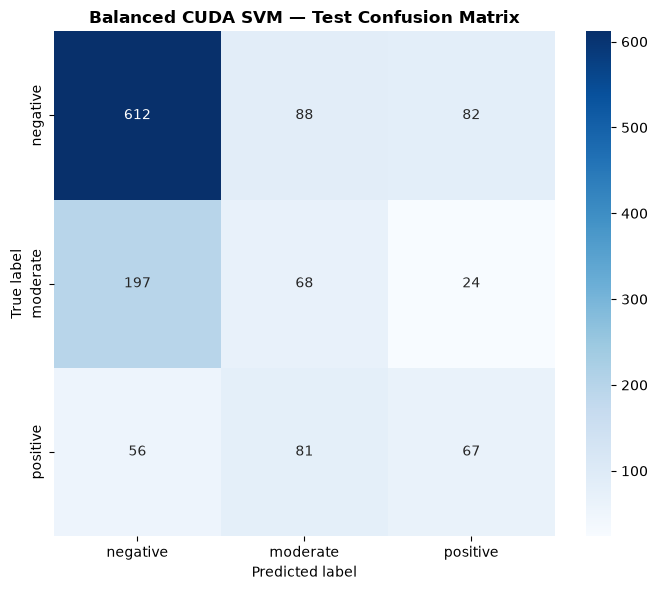

In [9]:
X_trainval_all = np.vstack([X_train_all, X_val])
y_trainval_all = np.concatenate([y_train_all, y_val])
trainval_groups_all = np.concatenate([train_groups, val_groups])
trainval_paths_all = train_paths + val_paths

X_trainval, y_trainval, _, _, final_balance_indices = make_exactly_balanced(
    X_trainval_all,
    y_trainval_all,
    trainval_groups_all,
    trainval_paths_all,
    random_state=SEED + 1000,
)
final_counts = np.bincount(y_trainval, minlength=len(CLASS_NAMES))
assert final_counts[0] == final_counts[1] == final_counts[2]
print(f'Final refit balance: {dict(zip(CLASS_NAMES, final_counts.tolist()))}')

final_scaler = CudaStandardScaler()
X_trainval_scaled = final_scaler.fit_transform(X_trainval)
X_test_final = final_scaler.transform(X_test)
del X_trainval
gc.collect()

final_component_models = []
for component_index, config in enumerate(selected_configs):
    print(f'\nFitting final voting component {component_index + 1}/{len(selected_configs)}')
    component = make_model(config, SEED + 2000 + component_index * 100)
    component.fit(X_trainval_scaled, y_trainval)
    final_component_models.append(component)
final_model = SoftVotingSVM(final_component_models, selected_weights)

test_predictions = final_model.predict(X_test_final)
test_probabilities = final_model.predict_proba(X_test_final)
test_accuracy = accuracy_score(y_test, test_predictions)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average='macro')
test_log_loss = log_loss(y_test, test_probabilities, labels=np.arange(len(CLASS_NAMES)))

print('=' * 64)
print(f'Test accuracy          : {test_accuracy:.4f} (f2: {REFERENCE_TEST_ACCURACY:.4f})')
print(f'Test balanced accuracy : {test_balanced_accuracy:.4f}')
print(f'Test macro-F1          : {test_macro_f1:.4f} (f2: {REFERENCE_TEST_MACRO_F1:.4f})')
print(f'Test log-loss          : {test_log_loss:.4f}')
print('=' * 64)

print(classification_report(
    y_test,
    test_predictions,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(7, 6))
matrix = confusion_matrix(y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Balanced CUDA SVM — Test Confusion Matrix', fontweight='bold')
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
plt.tight_layout()
plt.show()

## 8. Classification Report & Confusion Matrices

This section follows the presentation used in the CNN notebook: a complete test classification report followed by side-by-side validation and test confusion matrices. Validation uses the held-out selection ensemble; test uses the final balanced refit.

Test Set — Classification Report
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       0.71      0.78      0.74       782
    moderate       0.29      0.24      0.26       289
    positive       0.39      0.33      0.36       204

    accuracy                           0.59      1275
   macro avg       0.46      0.45      0.45      1275
weighted avg       0.56      0.59      0.57      1275



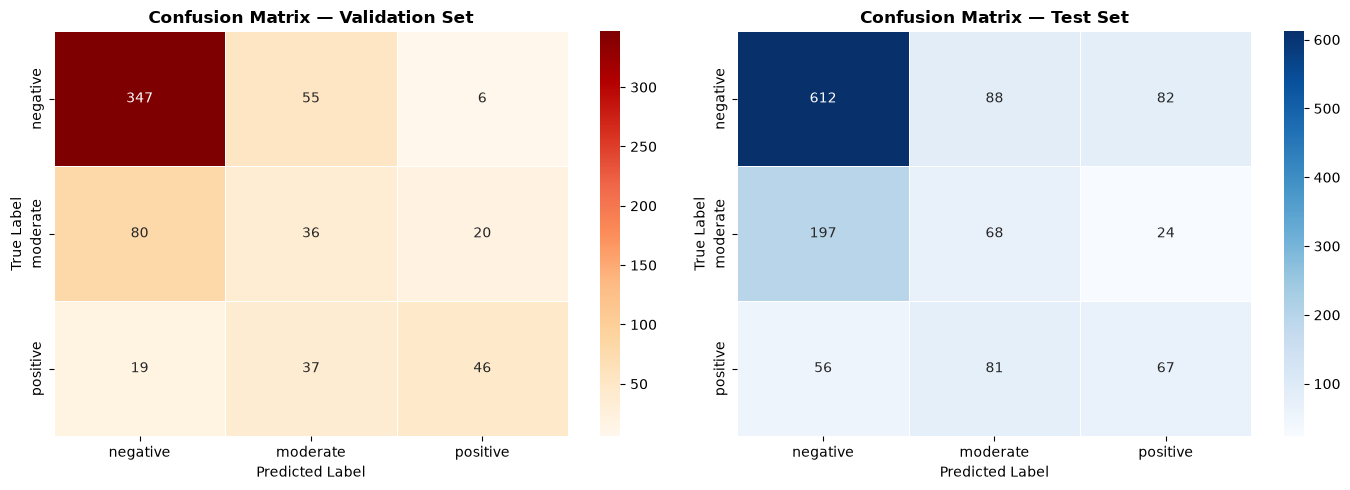

Classification report CSV: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4\test_classification_report.csv
Confusion matrices      : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4\confusion_matrices.png


In [10]:
print('Test Set — Classification Report')
print('─' * 60)
print(classification_report(
    y_test,
    test_predictions,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

test_classification_report = pd.DataFrame(classification_report(
    y_test,
    test_predictions,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
    output_dict=True,
)).T
classification_report_path = OUTPUT_DIR / 'test_classification_report.csv'
test_classification_report.to_csv(classification_report_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, predictions, true_labels, title, colour_map in [
    (axes[0], val_predictions, y_val, 'Confusion Matrix — Validation Set', 'OrRd'),
    (axes[1], test_predictions, y_test, 'Confusion Matrix — Test Set', 'Blues'),
]:
    matrix = confusion_matrix(
        true_labels, predictions, labels=np.arange(len(CLASS_NAMES))
    )
    sns.heatmap(
        matrix,
        annot=True,
        fmt='d',
        cmap=colour_map,
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        linewidths=0.5,
        ax=ax,
    )
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
confusion_path = OUTPUT_DIR / 'confusion_matrices.png'
plt.savefig(confusion_path, dpi=130, bbox_inches='tight')
plt.show()
print(f'Classification report CSV: {classification_report_path.resolve()}')
print(f'Confusion matrices      : {confusion_path.resolve()}')

## 8b. Final Error Report — Train / Validation / Test

A consolidated report styled like the CNN notebook. Training is measured on the exactly balanced train+validation refit matrix, validation is the held-out model-selection result, and test is the untouched final evaluation. `Error = 1 − accuracy`.

  FINAL ERROR REPORT  —  model = balanced CUDA soft-voting SVM
  Split          Samples         Loss     Accuracy        Error
  --------------------------------------------------------------------
  Training         9,384       0.0114      99.95%        0.05%
  Validation         646       1.5466      66.41%       33.59%
  Test             1,275       2.6111      58.59%       41.41%


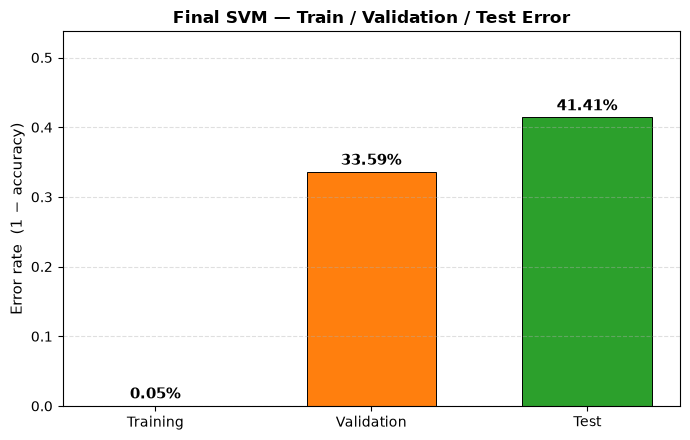

Report CSV: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4\final_error_report.csv
Report plot: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4\final_error_report.png


In [11]:
train_report_probabilities = final_model.predict_proba(X_trainval_scaled)
train_report_predictions = train_report_probabilities.argmax(axis=1)

train_report_loss = log_loss(
    y_trainval, train_report_probabilities, labels=np.arange(len(CLASS_NAMES))
)
train_report_accuracy = accuracy_score(y_trainval, train_report_predictions)
validation_report_loss = log_loss(
    y_val, val_probabilities, labels=np.arange(len(CLASS_NAMES))
)
validation_report_accuracy = accuracy_score(y_val, val_predictions)

report_rows = [
    ('Training', len(y_trainval), train_report_loss, train_report_accuracy, 1 - train_report_accuracy),
    ('Validation', len(y_val), validation_report_loss, validation_report_accuracy, 1 - validation_report_accuracy),
    ('Test', len(y_test), test_log_loss, test_accuracy, 1 - test_accuracy),
]

print('=' * 72)
print('  FINAL ERROR REPORT  —  model = balanced CUDA soft-voting SVM')
print('=' * 72)
print(f'  {"Split":<12}{"Samples":>10}{"Loss":>13}{"Accuracy":>13}{"Error":>13}')
print('  ' + '-' * 68)
for split_name, sample_count, loss_value, accuracy_value, error_value in report_rows:
    print(
        f'  {split_name:<12}{sample_count:>10,}{loss_value:>13.4f}'
        f'{accuracy_value:>12.2%}{error_value:>13.2%}'
    )
print('=' * 72)

final_error_df = pd.DataFrame(
    report_rows,
    columns=['split', 'samples', 'loss', 'accuracy', 'error'],
)
final_error_csv = OUTPUT_DIR / 'final_error_report.csv'
final_error_df.to_csv(final_error_csv, index=False)

split_names = [row[0] for row in report_rows]
error_rates = [row[4] for row in report_rows]
colours = ['#1f77b4', '#ff7f0e', '#2ca02c']
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    split_names, error_rates, color=colours,
    width=0.6, edgecolor='black', linewidth=0.7,
)
for bar, error_rate in zip(bars, error_rates):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.005,
        f'{error_rate:.2%}',
        ha='center', va='bottom', fontsize=11, fontweight='bold',
    )
ax.set_ylabel('Error rate  (1 − accuracy)', fontsize=11)
ax.set_title('Final SVM — Train / Validation / Test Error', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(error_rates) * 1.25 + 0.02)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
final_error_png = OUTPUT_DIR / 'final_error_report.png'
plt.savefig(final_error_png, dpi=130, bbox_inches='tight')
plt.show()
print(f'Report CSV: {final_error_csv.resolve()}')
print(f'Report plot: {final_error_png.resolve()}')

## 8c. Misclassified Validation Examples — Manual Error Analysis

Every validation mistake is printed, exported to `val_misclassified.csv`, assigned to a group member, and previewed in an image grid. Blank reason/fix columns are included for the written project report.

In [12]:
validation_true = np.asarray(y_val)
validation_predicted = np.asarray(val_predictions)
validation_misclassified_mask = validation_true != validation_predicted
validation_misclassified_indices = np.flatnonzero(validation_misclassified_mask)

print(f'Validation set size  : {len(validation_true):,}')
print(f'Correctly classified : {int((~validation_misclassified_mask).sum()):,}')
print(
    f'Misclassified        : {int(validation_misclassified_mask.sum()):,}  '
    f'({100 * validation_misclassified_mask.mean():.1f} %)'
)

augmented_root = AUGMENTED_DIR.resolve()
N_REPORT_MEMBERS = 4
validation_error_rows = []

for index in validation_misclassified_indices:
    path = Path(val_paths[index])
    try:
        is_augmented = path.resolve().is_relative_to(augmented_root)
    except Exception:
        is_augmented = 'aug' in str(path).lower()
    validation_error_rows.append({
        'val_index': int(index),
        'image_id': int(val_groups[index]),
        'file_name': path.name,
        'image_type': 'augmented' if is_augmented else 'real',
        'true_label': CLASS_NAMES[int(validation_true[index])],
        'pred_label': CLASS_NAMES[int(validation_predicted[index])],
        'error_type': (
            f'{CLASS_NAMES[int(validation_true[index])]} → '
            f'{CLASS_NAMES[int(validation_predicted[index])]}'
        ),
        'confidence': float(val_probabilities[index, validation_predicted[index]]),
        'file_path': str(path),
        'reason_category': '',
        'possible_reason': '',
        'suggested_fix': '',
    })

validation_misclassified_df = pd.DataFrame(validation_error_rows)
if len(validation_misclassified_df):
    per_member = int(np.ceil(len(validation_misclassified_df) / N_REPORT_MEMBERS))
    validation_misclassified_df['assigned_member'] = (
        np.arange(len(validation_misclassified_df)) // per_member
    ) + 1

print('\n' + '─' * 78)
print(f'  {"#":>4}  {"file_name":<40} {"type":<10} {"true":>10} → pred')
print('─' * 78)
for rank, row in validation_misclassified_df.iterrows():
    print(
        f'  {rank + 1:>4}  {row["file_name"]:<40} {row["image_type"]:<10} '
        f'{row["true_label"]:>10} → {row["pred_label"]}'
    )
print('─' * 78)

if len(validation_misclassified_df):
    print('\nError-type breakdown:')
    print(validation_misclassified_df['error_type'].value_counts().to_string())
    print('\nBreakdown by image type:')
    print(
        validation_misclassified_df.groupby(['image_type', 'error_type'])
        .size().rename('count').to_string()
    )

validation_misclassified_csv = OUTPUT_DIR / 'val_misclassified.csv'
validation_misclassified_df.to_csv(validation_misclassified_csv, index=False)
print(f'\nCSV saved → {validation_misclassified_csv.resolve()}')
display(validation_misclassified_df)

Validation set size  : 646
Correctly classified : 429
Misclassified        : 217  (33.6 %)

──────────────────────────────────────────────────────────────────────────────
     #  file_name                                type             true → pred
──────────────────────────────────────────────────────────────────────────────
     1  img101_autocontrast.jpg                  augmented    moderate → positive
     2  img101_brightness_down.jpg               augmented    moderate → positive
     3  img101_brightness_up.jpg                 augmented    moderate → positive
     4  img101_color_up.jpg                      augmented    moderate → positive
     5  img101_contrast_down.jpg                 augmented    moderate → positive
     6  img101_gaussian_blur.jpg                 augmented    moderate → positive
     7  img101_gaussian_noise.jpg                augmented    moderate → positive
     8  img101_grayscale_3ch.jpg                 augmented    moderate → positive
     9  img101_m

,val_index,image_id,file_name,image_type,true_label,pred_label,error_type,confidence,file_path,reason_category,possible_reason,suggested_fix,assigned_member
0,0,101,img101_autocontrast.jpg,augmented,moderate,positive,moderate → positive,0.648126,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
1,1,101,img101_brightness_down.jpg,augmented,moderate,positive,moderate → positive,0.621434,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
2,2,101,img101_brightness_up.jpg,augmented,moderate,positive,moderate → positive,0.602216,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
3,4,101,img101_color_up.jpg,augmented,moderate,positive,moderate → positive,0.584311,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
4,5,101,img101_contrast_down.jpg,augmented,moderate,positive,moderate → positive,0.669900,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,624,228,img228.jpg,real,negative,moderate,negative → moderate,0.975078,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,4
213,635,60,img60.jpg,real,negative,moderate,negative → moderate,0.651494,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,4
214,641,126,img126.jpg,real,positive,moderate,positive → moderate,0.999419,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,4
215,642,17,img17.jpg,real,positive,negative,positive → negative,0.819811,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,4


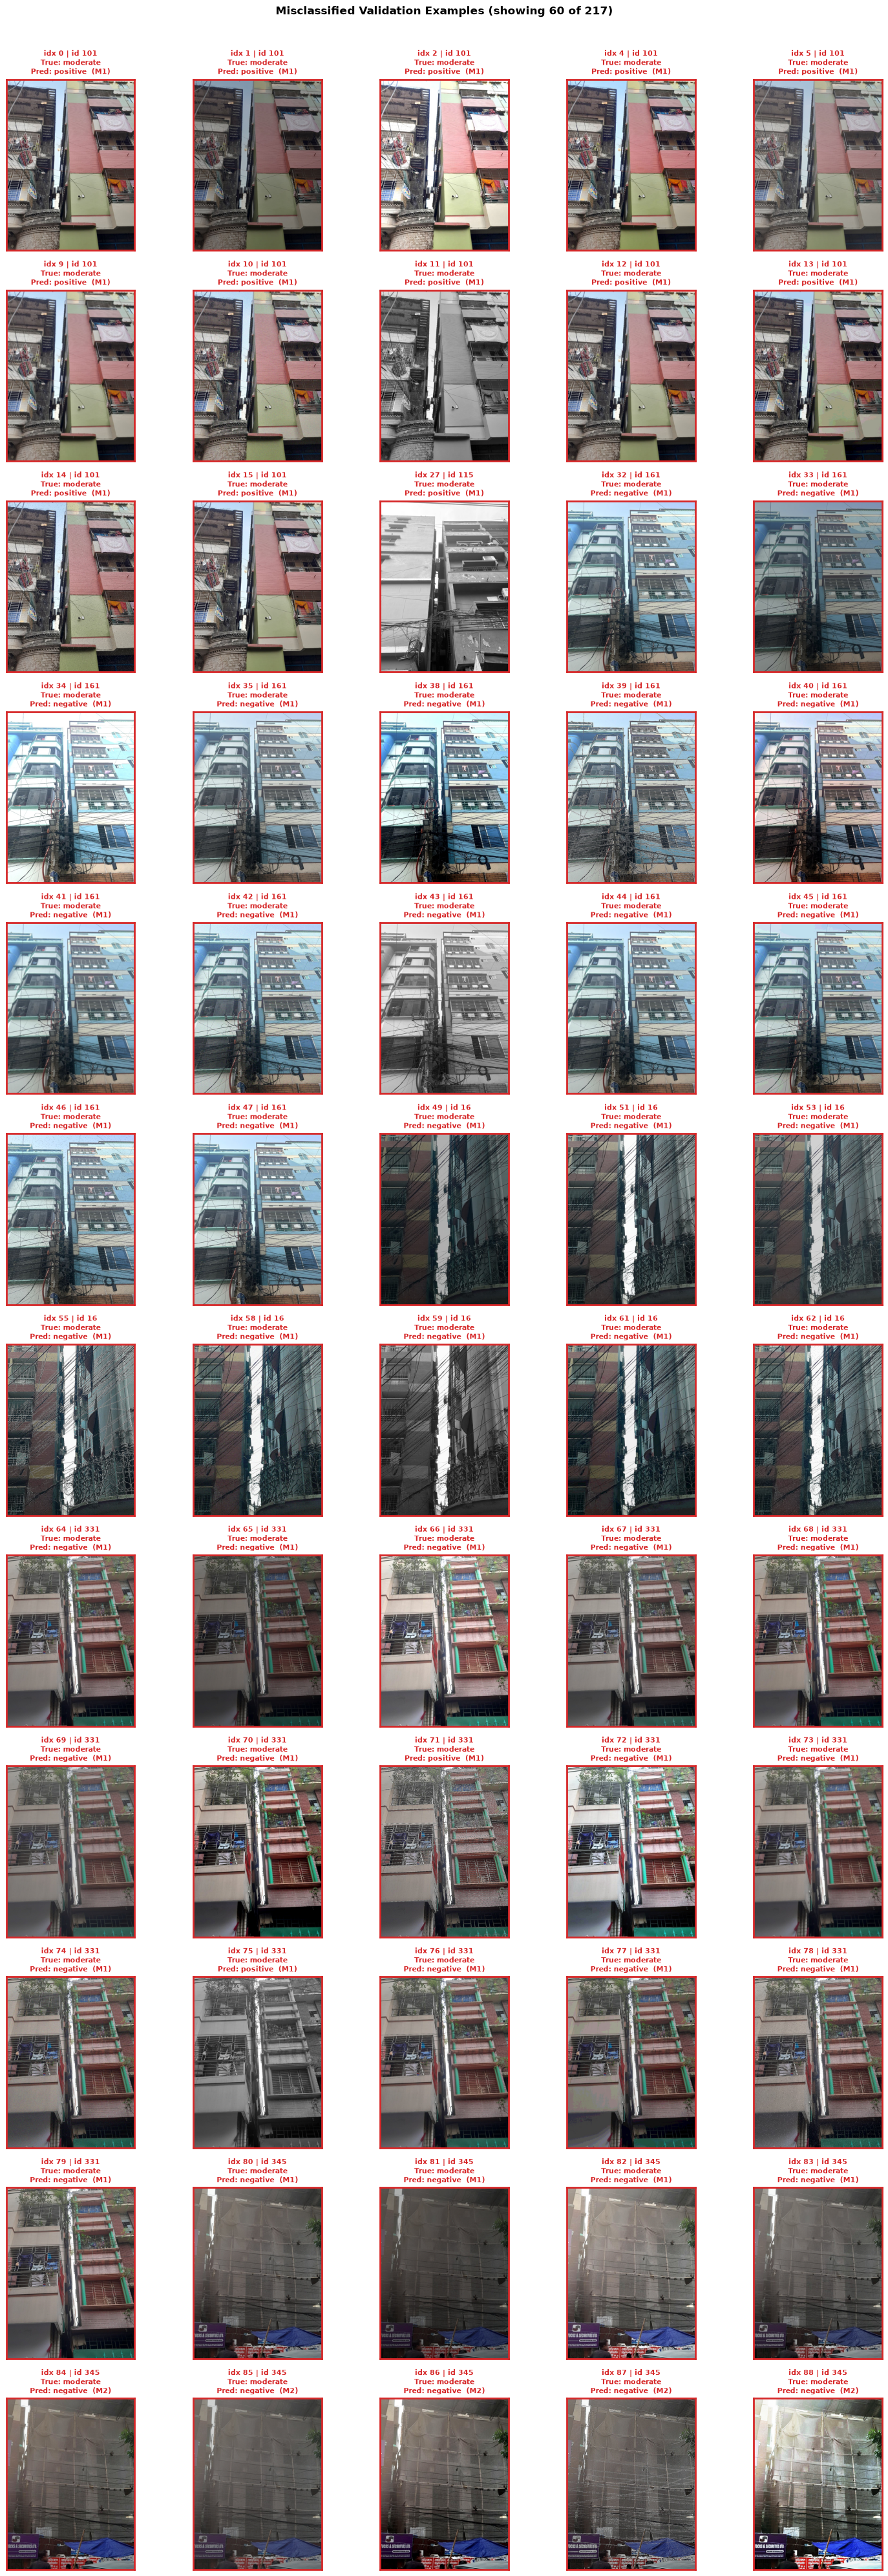

Grid saved to: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4\val_misclassified.png


In [13]:
MAX_VALIDATION_ERRORS_TO_DISPLAY = 60

if len(validation_misclassified_indices) == 0:
    print('No misclassified validation examples — nothing to display.')
else:
    display_indices = validation_misclassified_indices[:MAX_VALIDATION_ERRORS_TO_DISPLAY]
    columns = 5
    rows = int(np.ceil(len(display_indices) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns * 3.0, rows * 3.3))
    axes = np.asarray(axes).reshape(-1)
    for ax in axes:
        ax.axis('off')

    for plot_index, validation_index in enumerate(display_indices):
        ax = axes[plot_index]
        path = Path(val_paths[validation_index])
        with Image.open(path) as image:
            ax.imshow(image.convert('RGB'))
        row = validation_misclassified_df[
            validation_misclassified_df['val_index'] == validation_index
        ]
        member = int(row['assigned_member'].iloc[0]) if len(row) else '?'
        ax.set_title(
            f'idx {validation_index} | id {int(val_groups[validation_index])}\n'
            f'True: {CLASS_NAMES[int(validation_true[validation_index])]}\n'
            f'Pred: {CLASS_NAMES[int(validation_predicted[validation_index])]}  (M{member})',
            fontsize=8, color='#d62728', fontweight='bold',
        )
        ax.set_xticks([])
        ax.set_yticks([])
        ax.axis('on')
        for spine in ax.spines.values():
            spine.set_edgecolor('#d62728')
            spine.set_linewidth(2)

    fig.suptitle(
        f'Misclassified Validation Examples '
        f'(showing {len(display_indices)} of {len(validation_misclassified_indices)})',
        fontsize=12, fontweight='bold', y=1.005,
    )
    plt.tight_layout()
    validation_grid_path = OUTPUT_DIR / 'val_misclassified.png'
    plt.savefig(validation_grid_path, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'Grid saved to: {validation_grid_path.resolve()}')

## 9. Export Every Misclassified Test Image

In [14]:
misclassified_indices = np.flatnonzero(test_predictions != y_test)
rows = []
for index in misclassified_indices:
    row = {
        'image_name': test_paths[index].name,
        'image_path': str(test_paths[index]),
        'image_id': int(test_groups[index]),
        'true_label': CLASS_NAMES[int(y_test[index])],
        'predicted_label': CLASS_NAMES[int(test_predictions[index])],
        'confidence': float(test_probabilities[index, test_predictions[index]]),
    }
    for class_index, class_name in enumerate(CLASS_NAMES):
        row[f'probability_{class_name}'] = float(test_probabilities[index, class_index])
    rows.append(row)

misclassified_df = pd.DataFrame(rows, columns=[
    'image_name', 'image_path', 'image_id', 'true_label', 'predicted_label',
    'confidence', *[f'probability_{name}' for name in CLASS_NAMES],
])
misclassified_df.to_csv(MISCLASSIFIED_CSV, index=False)
print(f'Misclassified: {len(misclassified_df):,}/{len(y_test):,}')
print(f'CSV saved to: {MISCLASSIFIED_CSV.resolve()}')
display(misclassified_df)

Misclassified: 528/1,275
CSV saved to: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4\misclassified_images_balanced_cuda_svm.csv


,image_name,image_path,image_id,true_label,predicted_label,confidence,probability_negative,probability_moderate,probability_positive
0,img114_autocontrast.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,moderate,negative,0.695774,0.695774,2.256136e-01,7.861220e-02
1,img114_brightness_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,moderate,negative,0.769597,0.769597,2.173004e-01,1.310232e-02
2,img114_color_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,moderate,negative,0.535308,0.535308,3.506259e-01,1.140660e-01
3,img114_color_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,moderate,negative,0.756601,0.756601,1.737357e-01,6.966351e-02
4,img114_contrast_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,moderate,negative,0.757478,0.757478,1.093736e-01,1.331488e-01
...,...,...,...,...,...,...,...,...,...
523,img265.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,265,positive,negative,0.996232,0.996232,6.271273e-07,3.767547e-03
524,img274.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,274,positive,negative,0.968968,0.968968,3.102847e-02,3.313635e-06
525,img297.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,297,positive,moderate,0.994871,0.000680,9.948706e-01,4.449529e-03
526,img35.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,35,positive,moderate,0.991342,0.008658,9.913419e-01,1.039400e-09


## 10. Bias–Variance Graph

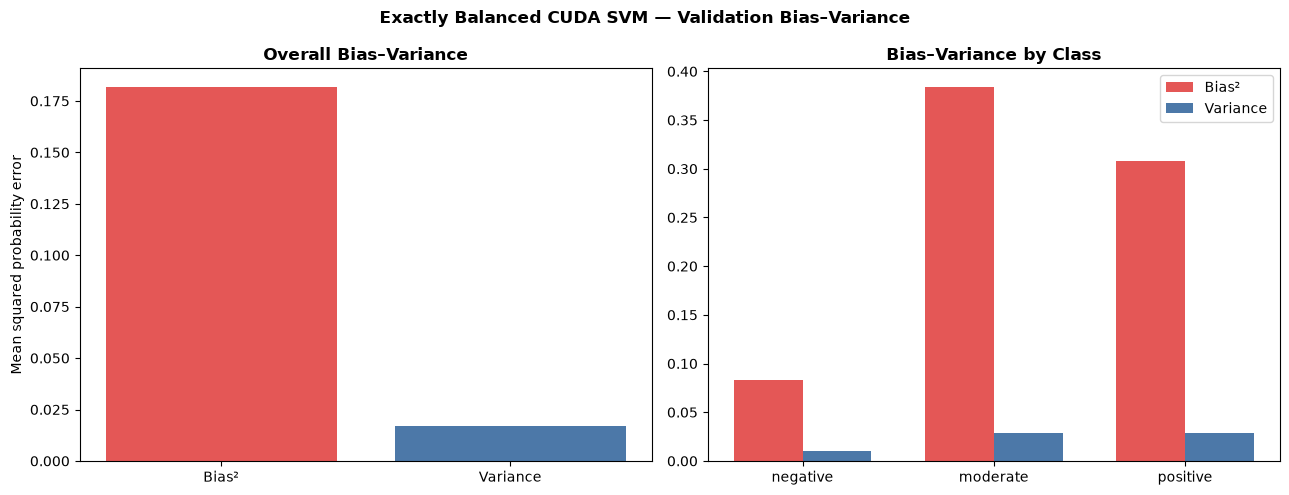

Bias²: 0.181756 | Variance: 0.016911
Graph saved to: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4\bias_variance_balanced_cuda_svm.png


In [15]:
all_member_probabilities = []
for component_model in selection_model.models_:
    for estimator, feature_indices in zip(
        component_model.estimators_, component_model.estimators_features_
    ):
        all_member_probabilities.append(
            estimator.predict_proba(X_val_scaled[:, feature_indices])
        )
member_probabilities = np.stack(all_member_probabilities)
mean_probabilities = member_probabilities.mean(axis=0)
one_hot = np.eye(len(CLASS_NAMES))[y_val]
bias_squared_samples = np.mean((mean_probabilities - one_hot) ** 2, axis=1)
variance_samples = np.mean(
    np.mean((member_probabilities - mean_probabilities[None]) ** 2, axis=2),
    axis=0,
)

overall_bias_squared = bias_squared_samples.mean()
overall_variance = variance_samples.mean()
class_bias = [bias_squared_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]
class_variance = [variance_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(['Bias²', 'Variance'], [overall_bias_squared, overall_variance],
            color=['#e45756', '#4c78a8'])
axes[0].set_title('Overall Bias–Variance', fontweight='bold')
axes[0].set_ylabel('Mean squared probability error')

positions = np.arange(len(CLASS_NAMES))
width = 0.36
axes[1].bar(positions - width/2, class_bias, width, label='Bias²', color='#e45756')
axes[1].bar(positions + width/2, class_variance, width, label='Variance', color='#4c78a8')
axes[1].set_xticks(positions)
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_title('Bias–Variance by Class', fontweight='bold')
axes[1].legend()

fig.suptitle('Exactly Balanced CUDA SVM — Validation Bias–Variance', fontweight='bold')
plt.tight_layout()
plt.savefig(BIAS_VARIANCE_PNG, dpi=160, bbox_inches='tight')
plt.show()
print(f'Bias²: {overall_bias_squared:.6f} | Variance: {overall_variance:.6f}')
print(f'Graph saved to: {BIAS_VARIANCE_PNG.resolve()}')

## 11. Performance Gate, Save, and Inference

In [16]:
accuracy_improved = test_accuracy > REFERENCE_TEST_ACCURACY
macro_f1_improved = test_macro_f1 > REFERENCE_TEST_MACRO_F1
performance_gate_passed = accuracy_improved and macro_f1_improved

artifact = {
    'model': final_model,
    'scaler': final_scaler,
    'selected_configs': selected_configs,
    'voting_weights': selected_weights,
    'class_names': CLASS_NAMES,
    'balance_target': BALANCE_TARGET,
    'balanced_counts': final_counts,
    'test_accuracy': test_accuracy,
    'test_balanced_accuracy': test_balanced_accuracy,
    'test_macro_f1': test_macro_f1,
    'performance_gate_passed': performance_gate_passed,
    'label_source': str(label_source),
    'feature_extractor': 'ImageNet pretrained ResNet18 frozen 1536-D multi-scale embedding',
}
save_path = MODEL_PATH if performance_gate_passed else OUTPUT_DIR / 'rajuk_balanced_cuda_svm_latest.pkl'
with open(save_path, 'wb') as file:
    pickle.dump(artifact, file)

if performance_gate_passed:
    print('PERFORMANCE GATE PASSED — improved model saved.')
else:
    print('PERFORMANCE GATE NOT PASSED — f2 remains the recommended model.')
    print('The latest f3 artifact was saved separately for inspection; no exception was raised.')
print(f'Model saved to: {save_path.resolve()}')
print(f'Accuracy gain: {test_accuracy - REFERENCE_TEST_ACCURACY:+.4f}')
print(f'Macro-F1 gain: {test_macro_f1 - REFERENCE_TEST_MACRO_F1:+.4f}')

PERFORMANCE GATE PASSED — improved model saved.
Model saved to: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\SVM\f4\rajuk_balanced_cuda_svm.pkl
Accuracy gain: +0.0392
Macro-F1 gain: +0.0316


In [17]:
def load_artifact(model_path=MODEL_PATH):
    with open(model_path, 'rb') as file:
        return pickle.load(file)

def predict_image(image_path, trained_artifact):
    with Image.open(image_path) as image:
        tensor = image_transform(image.convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.inference_mode(), torch.autocast(device_type='cuda', dtype=torch.float16):
        embedding = extract_multiscale_resnet_features(tensor)
    embedding = embedding.float().cpu().numpy()
    scaled = trained_artifact['scaler'].transform(embedding)
    probabilities = trained_artifact['model'].predict_proba(scaled)[0]
    predicted_index = int(np.argmax(probabilities))
    return {
        'prediction': trained_artifact['class_names'][predicted_index],
        'confidence': float(probabilities[predicted_index]),
        'probabilities': dict(zip(
            trained_artifact['class_names'], probabilities.astype(float)
        )),
    }

# Example:
# trained_artifact = load_artifact()
# print(predict_image(PROJECT_ROOT / 'new_image.jpg', trained_artifact))